In [ ]:
import sys

recommended = (3, 10)
current = sys.version_info[:2]

if current < recommended:
    print(f"You are using Python {current[0]}.{current[1]}. Python {recommended[0]}.{recommended[1]} or later is recommended.")
else:
    print(f"Python {current[0]}.{current[1]} — looks good!")

Python 3.13 — looks good!


In [ ]:
# Install required packages.
# Uncomment the lines below the first time you run this notebook to install dependencies,
# then re-comment them on subsequent runs.


%pip install --upgrade 'qiskit[visualization]>=2.5.0' qiskit-aer qiskit-ibm-runtime matplotlib
%pip install --upgrade qc-grader
%pip install --upgrade pymatching scikit-learn
# Optional, for GPU training of the neural decoder (an RTX 50-series card needs a recent CUDA build):
# %pip install torch --index-url https://download.pytorch.org/whl/cu128

In [ ]:
import os
import platform
import shutil
import subprocess
import sys

import qc_grader
import qiskit

from qc_grader.challenges.qgss_2026 import check_progress
from qc_grader.challenges.qgss_2026.lab0 import (
    grade_lab0_ex1,
    grade_lab0_ex2,
    grade_lab0_ex3,
    grade_lab0_ex4,
)


from qiskit.circuit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit.visualization import array_to_latex, plot_histogram, plot_state_qsphere
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime import Batch, QiskitRuntimeService
from qiskit_ibm_runtime import EstimatorV2 as Estimator
from qiskit_ibm_runtime import SamplerV2 as Sampler

import matplotlib.pyplot as plt

print(f"Qiskit version: {qiskit.__version__}")
print(f"Grader version: {qc_grader.__version__}")

Qiskit version: 2.6.2
Grader version: 2026.11.3


In [ ]:
# Paste your IBM Cloud credentials here ONCE, run the cell, then delete them again.
# Your account is already saved on this machine, so normally leave everything commented
# and just load the service below.

token = "f1SJYAyWSFAwjrp93Oo7t93KbogCbN5McGhGTwZwmmpf"
instance = "crn:v1:bluemix:public:quantum-computing:us-east:a/4f673943e73646b299487938b3680155:d8eda937-b9a8-4a6c-9eb6-3e7ad61dca1a::"  # looks like "crn:v1:bluemix:public:quantum-computing:..."
QiskitRuntimeService.save_account(
     token=token,
     instance=instance,
     overwrite=True,
     set_as_default=True,
 )

# Verify
service = QiskitRuntimeService()
backends = service.backends()
print(f"Account OK. {len(backends)} backend(s) available:")
for b in backends[:5]:
    print(f"  {b.name} ({b.num_qubits} qubits)")

Account OK. 3 backend(s) available:
  ibm_fez (156 qubits)
  ibm_kingston (156 qubits)
  ibm_marrakesh (156 qubits)


# Snoopy Codes: learning a chip's noise

**Plan:** an open, retrainable decoder that learns a specific IBM chip's noise from its own measurement data.

1. **Part 1, surface code (exact).** Enumerate every bit-flip pattern on the 3×3 surface code, decode it, and sort the outcomes. Then check the same parity checks in a Qiskit circuit.
2. **Part 2, repetition code on real IBM noise.** Build a repetition-code memory experiment in Qiskit, simulate it with noise copied from a **real IBM backend's calibration data**, and compare five decoders: no decoding, PyMatching with uniform weights, PyMatching with weights fitted from data, a lookup table, and a neural network.
3. **Sim-to-real.** Pretrain the network on one chip's simulated noise, then fine-tune on a small amount of data from a different chip.

> **QPU safety:** nothing in this notebook uses QPU time unless you set `RUN_ON_HARDWARE = True` in the settings cell. Loading a backend's calibration with `service.backend(...)` and simulating it with `AerSimulator.from_backend(...)` runs on your own computer and is free.

In [ ]:
# ---- Settings ----
import math, json, time, itertools, copy
import numpy as np

RUN_ON_HARDWARE = True          # True spends QPU minutes. Leave False until the simulated results look right.
BACKEND_NAME = "ibm_kingston"    # real chip whose calibration noise we simulate (free)
SECOND_BACKEND = "ibm_fez"       # a different chip, used as the "new device" in the sim-to-real test

D_LIST = [3, 5]                  # code distances (d=5 is slower to simulate; start with [3])
R_LIST = [1, 2, 3, 4, 6]         # rounds of parity checks
SHOTS = 20_000                   # simulated runs per (d, r) setting, split 50/50 between b=0 and b=1
PRETRAIN_SHOTS = 100_000         # simulated runs for pretraining the network in the sim-to-real test
FINETUNE_SHOTS = 4_000           # "small real dataset" size in the sim-to-real test
TEST_FRACTION = 0.2              # held out, never used for training or weight fitting
SEED = 2026
rng = np.random.default_rng(SEED)

## Part 1: does the 3×3 surface code beat a single qubit?

We check **all 512** ways the 9 data qubits can be bit-flipped, decode each with a minimum-weight lookup table, and add up exactly how likely failure is. Bit flips only; checks assumed perfect.

```
Data qubits     Z-checks (catch bit flips)
 0 1 2          Z0 Z3,  Z1 Z2 Z4 Z5,  Z3 Z4 Z6 Z7,  Z5 Z8
 3 4 5
 6 7 8          Logical value = parity of the top row (0, 1, 2)
```

In [ ]:
CHECKS = [[0, 3], [1, 2, 4, 5], [3, 4, 6, 7], [5, 8]]
TOP_ROW = [0, 1, 2]

def syndrome(flips):
    return tuple(sum(flips[q] for q in check) % 2 for check in CHECKS)

ALL_PATTERNS = list(itertools.product([0, 1], repeat=9))
DECODER = {}
for flips in ALL_PATTERNS:
    s = syndrome(flips)
    if s not in DECODER or sum(flips) < sum(DECODER[s]):
        DECODER[s] = flips

def outcome(errors):
    """Sort an error pattern into one of five outcomes."""
    if sum(errors) == 0:
        return "no error"
    fix = DECODER[syndrome(errors)]
    leftover = [e ^ f for e, f in zip(errors, fix)]
    lost = sum(leftover[q] for q in TOP_ROW) % 2 == 1
    detected = any(syndrome(errors))
    if detected:
        return "detected, miscorrected" if lost else "detected and fixed"
    return "undetected, logical" if lost else "undetected, harmless"

def flips_on(*dots):
    return tuple(1 if i in dots else 0 for i in range(9))

assert all(outcome(flips_on(q)) == "detected and fixed" for q in range(9))
assert outcome(flips_on(0, 6)) == "detected, miscorrected"
assert outcome(flips_on(1, 2)) == "undetected, harmless"

OUTCOMES = ["no error", "detected and fixed", "detected, miscorrected", "undetected, harmless", "undetected, logical"]
COUNTS = {o: [0] * 10 for o in OUTCOMES}
for flips in ALL_PATTERNS:
    COUNTS[outcome(flips)][sum(flips)] += 1
FAIL_COUNTS = [a + b for a, b in zip(COUNTS["detected, miscorrected"], COUNTS["undetected, logical"])]
print("Failing patterns by number of flips:", FAIL_COUNTS)

def prob(counts, p):
    return sum(c * p**k * (1 - p)**(9 - k) for k, c in enumerate(counts))

lo, hi = 1e-6, 0.5
for _ in range(100):
    mid = (lo + hi) / 2
    lo, hi = (mid, hi) if prob(FAIL_COUNTS, mid) < mid else (lo, mid)
crossover = lo
print(f"Surface code beats a single qubit when p < {crossover:.4f}")

print(f"\n{'outcome (%)':<24}" + "".join(f"p={p:<9}" for p in [0.001, 0.01, 0.05, 0.1]))
for o in OUTCOMES:
    print(f"{o:<24}" + "".join(f"{100*prob(COUNTS[o], p):<11.4f}" for p in [0.001, 0.01, 0.05, 0.1]))

Failing patterns by number of flips: [0, 0, 18, 56, 57, 69, 28, 18, 9, 1]
Surface code beats a single qubit when p < 0.0753

outcome (%)             p=0.001    p=0.01     p=0.05     p=0.1      
no error                99.1036    91.3517    63.0249    38.7420    
detected and fixed      0.8944     8.4565     32.9370    48.3018    
detected, miscorrected  0.0018     0.1723     3.6128     11.5410    
undetected, harmless    0.0002     0.0186     0.3516     0.9867     
undetected, logical     0.0000     0.0008     0.0736     0.4284     


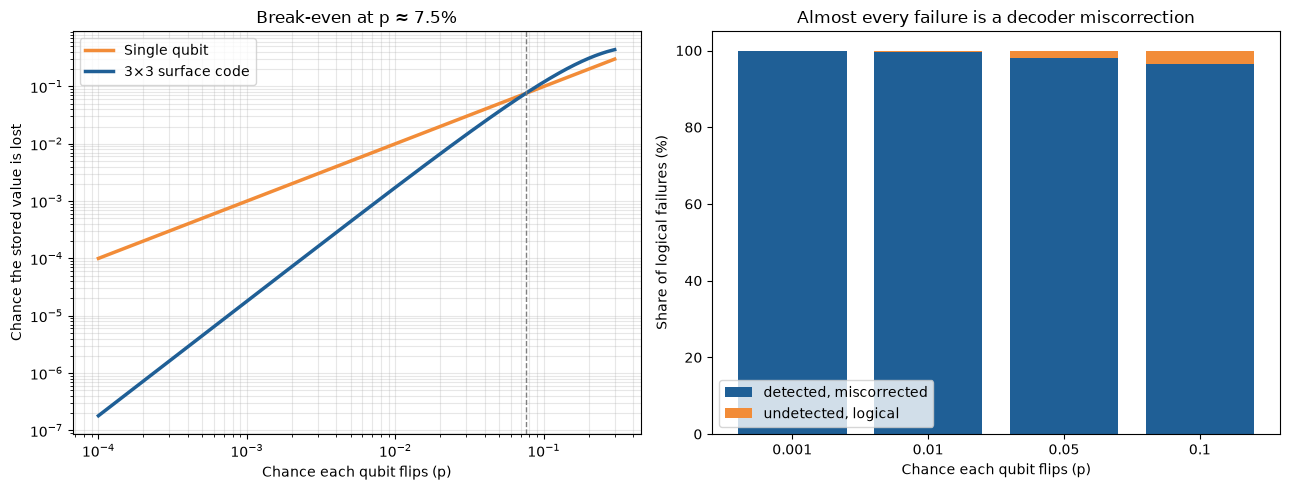

In [ ]:
import matplotlib.pyplot as plt
ps = np.logspace(-4, np.log10(0.3), 400)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(ps, ps, label="Single qubit", color="#F28C38", lw=2.5)
axes[0].plot(ps, [prob(FAIL_COUNTS, p) for p in ps], label="3×3 surface code", color="#1F5F96", lw=2.5)
axes[0].axvline(crossover, color="gray", ls="--", lw=1)
axes[0].set(xscale="log", yscale="log", xlabel="Chance each qubit flips (p)", ylabel="Chance the stored value is lost",
            title=f"Break-even at p ≈ {crossover*100:.1f}%")
axes[0].legend(); axes[0].grid(alpha=0.3, which="both")

p_bar = [0.001, 0.01, 0.05, 0.1]
fail_parts = {"detected, miscorrected": "#1F5F96", "undetected, logical": "#F28C38"}
bottom = np.zeros(len(p_bar))
for o, col in fail_parts.items():
    share = np.array([prob(COUNTS[o], p) / prob(FAIL_COUNTS, p) for p in p_bar])
    axes[1].bar([str(p) for p in p_bar], 100 * share, bottom=100 * bottom, color=col, label=o)
    bottom += share
axes[1].set(xlabel="Chance each qubit flips (p)", ylabel="Share of logical failures (%)",
            title="Almost every failure is a decoder miscorrection")
axes[1].legend()
plt.tight_layout(); plt.savefig("part1_surface_code.png", dpi=200); plt.show()

### Part 1b: the same checks as a Qiskit circuit

We build the four Z-checks with ancilla qubits, inject X errors, and confirm the measured syndromes match the enumeration exactly (ideal simulator, runs locally).

All 12 injected-error syndromes match the enumeration.


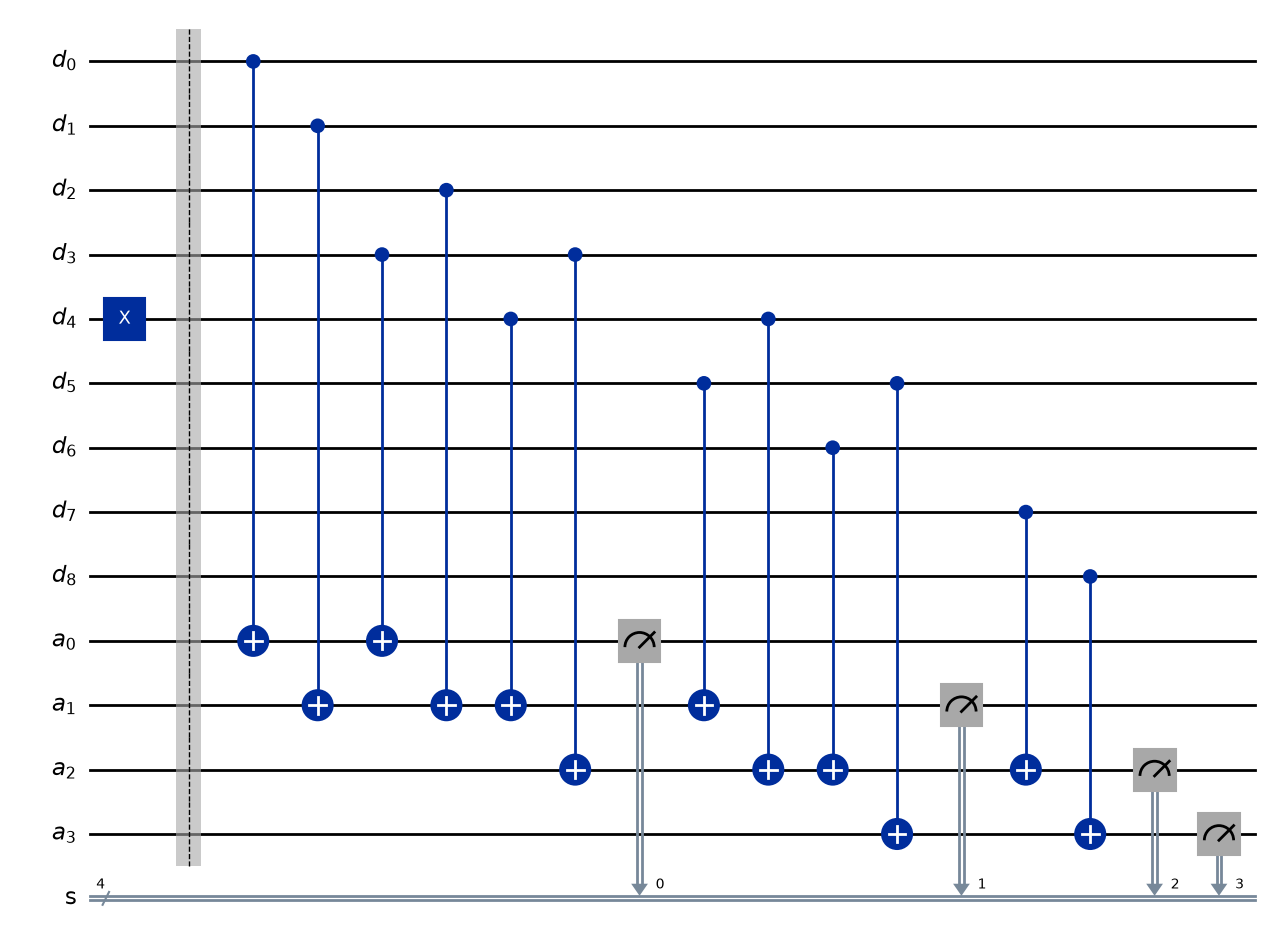

In [ ]:
from qiskit import QuantumRegister, ClassicalRegister

def z_check_circuit(flips):
    data, anc, s = QuantumRegister(9, "d"), QuantumRegister(4, "a"), ClassicalRegister(4, "s")
    qc = QuantumCircuit(data, anc, s)
    for q, f in enumerate(flips):
        if f:
            qc.x(data[q])
    qc.barrier()
    for k, check in enumerate(CHECKS):
        for q in check:
            qc.cx(data[q], anc[k])
    qc.measure(anc, s)
    return qc

ideal_sim = AerSimulator()
tests = [flips_on(q) for q in range(9)] + [flips_on(0, 6), flips_on(1, 2), flips_on(1, 4, 7)]
for pattern in tests:
    counts = ideal_sim.run(z_check_circuit(pattern), shots=1).result().get_counts()
    measured = tuple(int(bit) for bit in list(counts)[0][::-1])   # Qiskit prints bit 0 last
    assert measured == syndrome(pattern), (pattern, measured)
print(f"All {len(tests)} injected-error syndromes match the enumeration.")
z_check_circuit(flips_on(4)).draw("mpl")

### Why Part 2 uses a repetition code on IBM hardware

IBM chips use a **heavy-hex** layout (at most 3 neighbours per qubit). The cell below transpiles the surface-code checks and a repetition code onto the real backend's layout and compares the cost. This only compiles circuits; nothing runs.

In [ ]:
real_backend = service.backend(BACKEND_NAME)   # reads the chip's layout and calibration; uses no QPU time
pm = generate_preset_pass_manager(optimization_level=3, backend=real_backend, seed_transpiler=SEED)

def two_qubit_count(qc):
    return sum(1 for inst in qc.data if inst.operation.num_qubits == 2)

def rep_check_round(d):
    data, anc = QuantumRegister(d, "data"), QuantumRegister(d - 1, "anc")
    qc = QuantumCircuit(data, anc, ClassicalRegister(d - 1))
    for i in range(d - 1): qc.cx(data[i], anc[i])
    for i in range(d - 1): qc.cx(data[i + 1], anc[i])
    qc.measure(anc, qc.clbits)
    return qc

for name, qc in [("Surface code Z-checks (d=3)", z_check_circuit(flips_on())),
                 ("Repetition code round (d=5)", rep_check_round(5))]:
    isa = pm.run(qc)
    print(f"{name:<30} logical 2-qubit gates: {two_qubit_count(qc):>3}   on {real_backend.name}: {two_qubit_count(isa):>3}")

Surface code Z-checks (d=3)    logical 2-qubit gates:  12   on ibm_kingston:  33
Repetition code round (d=5)    logical 2-qubit gates:   8   on ibm_kingston:   8


## Part 2: a repetition code under real IBM noise

**Code.** d data qubits in a line with d − 1 ancillas between them; ancilla i measures Z_i Z_{i+1}. Each run prepares logical bit b (all data qubits in |b⟩), does r rounds of parity checks with mid-circuit measurement and reset, then measures every data qubit. b alternates 50/50 so the |1⟩ state's extra decay is averaged in.

**Detectors** (the decoder's input), with m_{t,i} ancilla i's result in round t and q the final data readout:

| Detector | Definition |
|---|---|
| Round 1 | D = m_{1,i} |
| Rounds 2..r | D = m_{t,i} ⊕ m_{t−1,i} |
| Final | D = (q_i ⊕ q_{i+1}) ⊕ m_{r,i} |

**Label:** y = q_0 ⊕ b, "did the logical bit flip?". A logical error is a wrong prediction of y.

**Noise:** `AerSimulator.from_backend(real_backend)` copies the real chip's current per-qubit T1/T2, gate errors and readout errors into a local simulator. Free, and the same circuits later run unchanged on the real chip.

Simulating with ibm_kingston's calibration data.


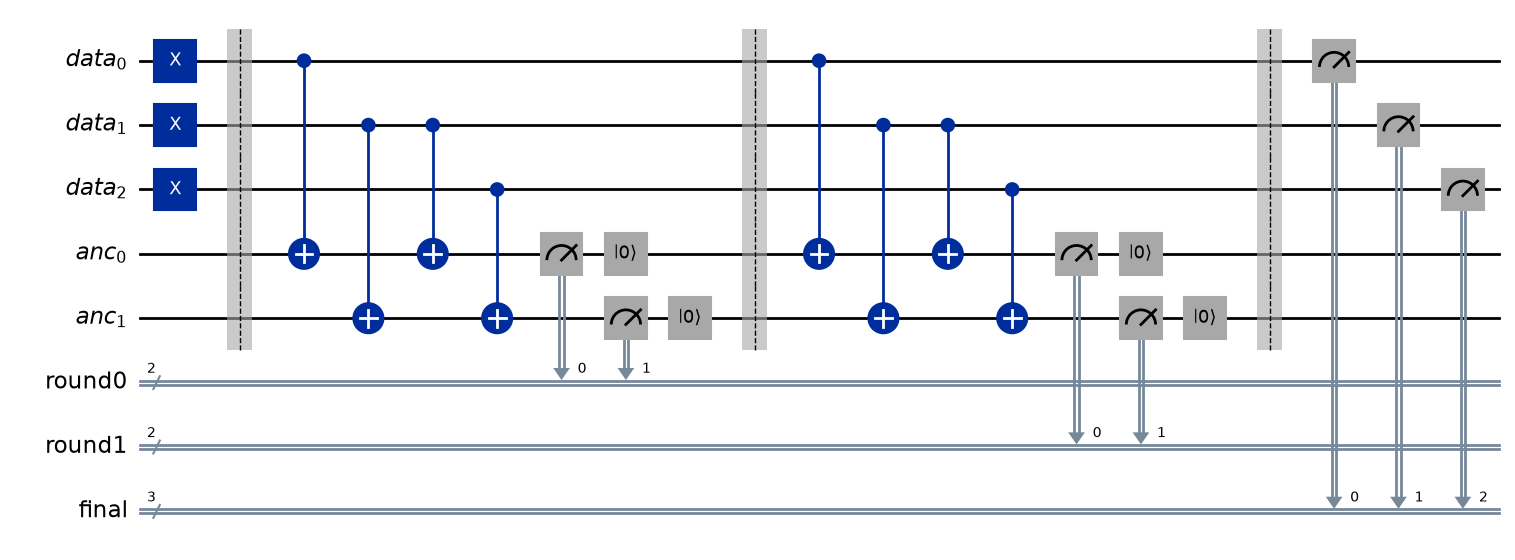

In [ ]:
noisy_sim = AerSimulator.from_backend(real_backend)    # local simulator with ibm_kingston's calibration noise
sim_sampler = Sampler(mode=noisy_sim)                  # same Sampler interface we will use on hardware
print(f"Simulating with {real_backend.name}'s calibration data.")

def repetition_code_circuit(d, r, b):
    data, anc = QuantumRegister(d, "data"), QuantumRegister(d - 1, "anc")
    rounds = [ClassicalRegister(d - 1, f"round{t}") for t in range(r)]
    final = ClassicalRegister(d, "final")
    qc = QuantumCircuit(data, anc, *rounds, final)
    if b:
        qc.x(data)
    qc.barrier()
    for t in range(r):
        for i in range(d - 1):            # CNOT layer 1: data i -> ancilla i
            qc.cx(data[i], anc[i])
        for i in range(d - 1):            # CNOT layer 2: data i+1 -> ancilla i
            qc.cx(data[i + 1], anc[i])
        qc.measure(anc, rounds[t])
        qc.reset(anc)
        qc.barrier()
    qc.measure(data, final)
    return qc

repetition_code_circuit(3, 2, b=1).draw("mpl", fold=-1)

### Sampling and detector extraction

In [ ]:
def bits(register_data):
    """BitArray -> (shots, n_bits) bool array, column k = bit k."""
    return register_data.to_bool_array(order="little")

def submit_rep_code(d, r, shots, sampler):
    circuits = [pm.run(repetition_code_circuit(d, r, b)) for b in (0, 1)]
    return sampler.run(circuits, shots=shots // 2)

def detectors_from_records(m, q):
    """m: (shots, r, d-1) ancilla results; q: (shots, d) final data readout. Returns (shots, (r+1)*(d-1))."""
    S, r, n = m.shape
    D = np.empty((S, r + 1, n), dtype=bool)
    D[:, 0] = m[:, 0]
    D[:, 1:r] = m[:, 1:] ^ m[:, :-1]
    D[:, r] = (q[:, :-1] ^ q[:, 1:]) ^ m[:, -1]
    return D.reshape(S, -1).astype(np.uint8)

def parse_rep_code(result, d, r):
    """Job result -> detectors D (shots, (r+1)(d-1)) and labels y (shots,)."""
    D_all, y_all = [], []
    for b, pub in zip((0, 1), result):
        m = np.stack([bits(getattr(pub.data, f"round{t}")) for t in range(r)], axis=1)
        q = bits(pub.data.final)
        D_all.append(detectors_from_records(m, q))
        y_all.append((q[:, 0] ^ bool(b)).astype(np.uint8))
    return np.concatenate(D_all), np.concatenate(y_all)

def train_test_split(D, y, test_fraction=TEST_FRACTION):
    perm = rng.permutation(len(y))
    cut = int(len(y) * (1 - test_fraction))
    return D[perm[:cut]], y[perm[:cut]], D[perm[cut:]], y[perm[cut:]]

# Check: with no noise every detector must be 0 and no logical flips occur
D0, y0 = parse_rep_code(submit_rep_code(3, 3, 200, Sampler(mode=AerSimulator())).result(), 3, 3)
assert D0.sum() == 0 and y0.sum() == 0
print("Noiseless check passed: all detectors 0.")

Noiseless check passed: all detectors 0.


### Decoders

| # | Decoder | What it knows |
|---|---|---|
| 0 | No decoding | Nothing (also shown: majority vote of the final data readout) |
| 1 | PyMatching, uniform weights | The graph; every edge equally likely |
| 2 | PyMatching, **weights fitted from data** | Edge probabilities estimated from detector statistics: the fair baseline |
| 3 | Lookup table | Most common label per detector pattern in the training data (small codes only) |
| 4 | **Neural net (ours)** | Learned from data alone |

Fitted weights use the pairwise estimator p_ij = ½ − √(¼ − (⟨x_i x_j⟩ − ⟨x_i⟩⟨x_j⟩) / (1 − 2⟨x_i⟩ − 2⟨x_j⟩ + 4⟨x_i x_j⟩)), plus p_iB = ½[1 − (1 − 2⟨x_i⟩) / Π_j(1 − 2p_ij)] for boundary edges. The graph includes space-like edges (data flips), time-like edges (measurement errors) and diagonal edges (a data flip between the two CNOT layers). These functions were tested against a separate simulation: every single fault lands on a graph edge, and the fit recovers planted error rates.

In [ ]:
import pymatching

def build_graph(d, r):
    """Edges of the matching graph: (u, v or None=boundary, flips_logical)."""
    n, R = d - 1, r + 1
    idx = lambda t, i: t * n + i
    edges = []
    for t in range(R):
        edges.append((idx(t, 0), None, True))            # data qubit 0 flip -> left boundary, flips the logical bit
        for j in range(1, d - 1):
            edges.append((idx(t, j - 1), idx(t, j), False))  # data qubit j flip
        edges.append((idx(t, n - 1), None, False))       # data qubit d-1 flip -> right boundary
    for t in range(R - 1):
        for i in range(n):
            edges.append((idx(t, i), idx(t + 1, i), False))      # ancilla measurement error
        for j in range(1, d - 1):
            edges.append((idx(t, j - 1), idx(t + 1, j), False))  # data flip between the two CNOT layers
    return edges

def fit_edge_probs(D, edges, eps=1e-6):
    X = D.astype(np.float64); mu = X.mean(0)
    probs = np.zeros(len(edges))
    for k, (u, v, _) in enumerate(edges):
        if v is None: continue
        xy = (X[:, u] * X[:, v]).mean()
        den = 1 - 2 * mu[u] - 2 * mu[v] + 4 * xy
        arg = 0.25 - (xy - mu[u] * mu[v]) / den
        probs[k] = np.clip(0.5 - math.sqrt(max(arg, 0.0)), eps, 0.499)
    for k, (u, v, _) in enumerate(edges):
        if v is not None: continue
        prod = np.prod([1 - 2 * probs[j] for j, (a, b, _) in enumerate(edges) if b is not None and u in (a, b)])
        probs[k] = np.clip(0.5 * (1 - (1 - 2 * mu[u]) / prod), eps, 0.499)
    return probs

def make_matching(edges, probs=None):
    m = pymatching.Matching()
    for k, (u, v, flips_logical) in enumerate(edges):
        p = 0.01 if probs is None else float(probs[k])    # uniform: every edge the same weight
        w = math.log((1 - p) / p)
        f = {0} if flips_logical else set()
        if v is None:
            m.add_boundary_edge(u, weight=w, fault_ids=f, error_probability=p)
        else:
            m.add_edge(u, v, weight=w, fault_ids=f, error_probability=p)
    return m

def pattern_keys(D):
    assert D.shape[1] <= 62, "too many detectors for a lookup table"
    return D.astype(np.int64) @ (np.int64(1) << np.arange(D.shape[1], dtype=np.int64))

def fit_lookup(D, y):
    keys = pattern_keys(D)
    uniq, inv = np.unique(keys, return_inverse=True)
    ones = np.bincount(inv, weights=y, minlength=len(uniq))
    tot = np.bincount(inv, minlength=len(uniq))
    return uniq, (ones > tot / 2).astype(np.uint8), tot

def predict_lookup(table, D, fallback, min_count=5):
    uniq, label, tot = table
    keys = pattern_keys(D)
    pos = np.clip(np.searchsorted(uniq, keys), 0, len(uniq) - 1)
    found = (uniq[pos] == keys) & (tot[pos] >= min_count)
    return np.where(found, label[pos], fallback).astype(np.uint8)

def logical_error_rate(pred, y):
    n = len(y); p = float(np.mean(pred != y))
    return p, math.sqrt(max(p * (1 - p), 1e-12) / n)

def mcnemar(pred_a, pred_b, y):
    b = int(np.sum((pred_a == y) & (pred_b != y)))
    c = int(np.sum((pred_a != y) & (pred_b == y)))
    stat = (b - c) ** 2 / max(b + c, 1)
    return b, c, math.erfc(math.sqrt(stat / 2))

def error_per_round(rs, pls):
    rs = np.asarray(rs, float); y = np.log(np.clip(1 - 2 * np.asarray(pls, float), 1e-9, None))
    slope, _ = np.polyfit(rs, y, 1)
    return 0.5 * (1 - math.exp(slope))

In [ ]:
try:
    import torch
    import torch.nn as nn
    HAVE_TORCH = True
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    torch.manual_seed(SEED)
except ImportError:
    HAVE_TORCH = False
    DEVICE = "cpu (scikit-learn)"
print("Neural decoder backend:", "PyTorch on " + DEVICE if HAVE_TORCH else DEVICE)

class NeuralDecoder:
    """Small MLP: detector bits in, probability that the logical bit flipped out."""
    def __init__(self, n_inputs, hidden=256):
        if HAVE_TORCH:
            self.net = nn.Sequential(nn.Linear(n_inputs, hidden), nn.ReLU(),
                                     nn.Linear(hidden, hidden), nn.ReLU(),
                                     nn.Linear(hidden, 1)).to(DEVICE)
        else:
            from sklearn.neural_network import MLPClassifier
            self.net = MLPClassifier(hidden_layer_sizes=(hidden, hidden), max_iter=40,
                                     early_stopping=True, random_state=SEED, warm_start=True)

    def fit(self, D, y, epochs=20, lr=1e-3, batch=4096):
        if not HAVE_TORCH:
            self.net.fit(D, y)
            return self
        X = torch.tensor(D, dtype=torch.float32, device=DEVICE)
        Y = torch.tensor(y, dtype=torch.float32, device=DEVICE)
        opt = torch.optim.Adam(self.net.parameters(), lr=lr)
        loss_fn = nn.BCEWithLogitsLoss()
        self.net.train()
        for _ in range(epochs):
            perm = torch.randperm(len(X), device=DEVICE)
            for s in range(0, len(X), batch):
                i = perm[s:s + batch]
                opt.zero_grad()
                loss_fn(self.net(X[i]).squeeze(1), Y[i]).backward()
                opt.step()
        return self

    def predict(self, D):
        if not HAVE_TORCH:
            return self.net.predict(D).astype(np.uint8)
        self.net.eval()
        with torch.no_grad():
            X = torch.tensor(D, dtype=torch.float32, device=DEVICE)
            return (self.net(X).squeeze(1) > 0).cpu().numpy().astype(np.uint8)

Neural decoder backend: PyTorch on cpu


In [ ]:
def evaluate_all(Dtr, ytr, Dte, yte, d, r, neural=None):
    """Fit every decoder on the training split, score on the test split. Returns {name: (LER, error bar, predictions)}."""
    n_det = Dtr.shape[1]
    edges = build_graph(d, r)
    out = {}
    out["0 No decoding"] = np.zeros_like(yte)
    out["1 PyMatching, uniform"] = make_matching(edges).decode_batch(Dte)[:, 0].astype(np.uint8)
    fitted = make_matching(edges, fit_edge_probs(Dtr, edges))
    pred_fit = fitted.decode_batch(Dte)[:, 0].astype(np.uint8)
    out["2 PyMatching, fitted"] = pred_fit
    if n_det <= 20:
        out["3 Lookup table"] = predict_lookup(fit_lookup(Dtr, ytr), Dte, fallback=pred_fit)
    if neural is None:
        neural = NeuralDecoder(n_det).fit(Dtr, ytr)
    out["4 Neural net"] = neural.predict(Dte)
    return {k: (*logical_error_rate(p, yte), p) for k, p in out.items()}, neural

def show(results, title=""):
    print(title)
    for k, (p, err, _) in results.items():
        print(f"  {k:<24} logical error {100*p:6.2f}% ± {100*err:.2f}%")

### Experiment 1: all decoders under real-chip noise

Sweeps d and r on the simulator with real calibration noise. The first setting prints its run time so you can scale `SHOTS` before the full sweep.

In [ ]:
results = {}            # (d, r) -> decoder results
datasets = {}           # keep the data for later experiments
for d in D_LIST:
    for r in R_LIST:
        t0 = time.time()
        D, y = parse_rep_code(submit_rep_code(d, r, SHOTS, sim_sampler).result(), d, r)
        datasets[(d, r)] = (D, y)
        Dtr, ytr, Dte, yte = train_test_split(D, y)
        results[(d, r)], _ = evaluate_all(Dtr, ytr, Dte, yte, d, r)
        show(results[(d, r)], f"d={d}, r={r}  ({time.time()-t0:.0f} s, {D.shape[1]} detectors)")

np.savez_compressed("rep_code_sim_data.npz",
                    **{f"D_d{d}_r{r}": v[0] for (d, r), v in datasets.items()},
                    **{f"y_d{d}_r{r}": v[1] for (d, r), v in datasets.items()})

d=3, r=1  (12 s, 4 detectors)
  0 No decoding            logical error   0.53% ± 0.11%
  1 PyMatching, uniform    logical error   0.03% ± 0.02%
  2 PyMatching, fitted     logical error   0.05% ± 0.04%
  3 Lookup table           logical error   0.05% ± 0.04%
  4 Neural net             logical error   0.10% ± 0.05%
d=3, r=2  (20 s, 6 detectors)
  0 No decoding            logical error   0.70% ± 0.13%
  1 PyMatching, uniform    logical error   0.03% ± 0.02%
  2 PyMatching, fitted     logical error   0.00% ± 0.00%
  3 Lookup table           logical error   0.00% ± 0.00%
  4 Neural net             logical error   0.20% ± 0.07%
d=3, r=3  (12 s, 8 detectors)
  0 No decoding            logical error   0.62% ± 0.12%
  1 PyMatching, uniform    logical error   0.05% ± 0.04%
  2 PyMatching, fitted     logical error   0.00% ± 0.00%
  3 Lookup table           logical error   0.00% ± 0.00%
  4 Neural net             logical error   0.62% ± 0.12%
d=3, r=4  (12 s, 10 detectors)
  0 No decoding         

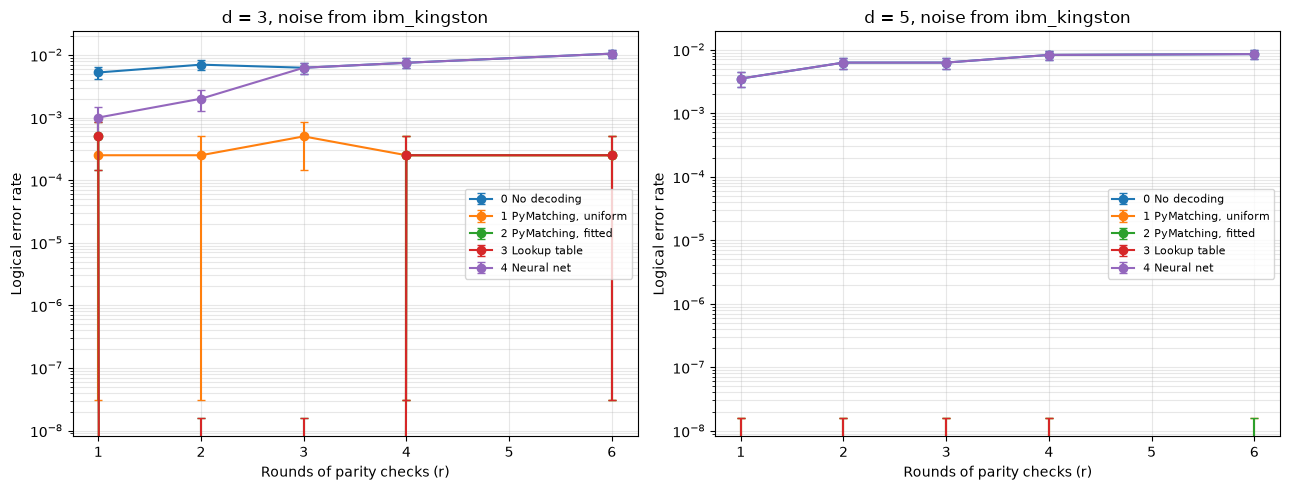

Logical error per round (fitted over r, Math check Q4):
  d=3  0 No decoding            0.097%
  d=3  1 PyMatching, uniform    -0.000%
  d=3  2 PyMatching, fitted     -0.001%
  d=3  3 Lookup table           -0.001%
  d=3  4 Neural net             0.202%
  d=5  0 No decoding            0.095%
  d=5  1 PyMatching, uniform    0.000%
  d=5  2 PyMatching, fitted     0.000%
  d=5  3 Lookup table           0.000%
  d=5  4 Neural net             0.095%

McNemar, d=3 r=6: fitted PyMatching right & net wrong = 24, net right & PyMatching wrong = 0, p = 0.000


In [ ]:
fig, axes = plt.subplots(1, len(D_LIST), figsize=(6.5 * len(D_LIST), 5), squeeze=False)
summary = {}
for ax, d in zip(axes[0], D_LIST):
    names = list(results[(d, R_LIST[0])].keys())
    for name in names:
        rs = [r for r in R_LIST if name in results[(d, r)]]
        pl = [results[(d, r)][name][0] for r in rs]
        er = [results[(d, r)][name][1] for r in rs]
        ax.errorbar(rs, pl, yerr=er, marker="o", capsize=3, label=name)
        if len(rs) >= 3 and max(pl) < 0.5:
            summary[(d, name)] = error_per_round(rs, pl)
    ax.set(xlabel="Rounds of parity checks (r)", ylabel="Logical error rate", yscale="log",
           title=f"d = {d}, noise from {real_backend.name}")
    ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("exp1_decoders_vs_rounds.png", dpi=200); plt.show()

print("Logical error per round (fitted over r, Math check Q4):")
for (d, name), eps in summary.items():
    print(f"  d={d}  {name:<24} {100*eps:.3f}%")

# Paired comparison of the two data-driven decoders at the largest setting
d, r = D_LIST[0], R_LIST[-1]
D, y = datasets[(d, r)]
Dtr, ytr, Dte, yte = train_test_split(D, y)
res, _ = evaluate_all(Dtr, ytr, Dte, yte, d, r)
b, c, pval = mcnemar(res["2 PyMatching, fitted"][2], res["4 Neural net"][2], yte)
print(f"\nMcNemar, d={d} r={r}: fitted PyMatching right & net wrong = {b}, net right & PyMatching wrong = {c}, p = {pval:.3f}")

### Experiment 2: learning curve (does the net reach the optimum?)

At d = 3, r = 3 there are only 8 detectors, so the lookup table is essentially optimal once it has seen enough data. If the net's curve meets the table's, it has learned all there is to learn from the data.

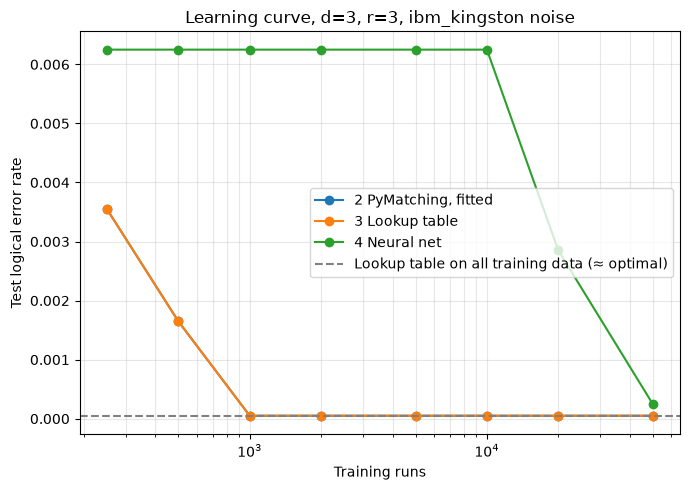

In [ ]:
d, r = 3, 3
D, y = parse_rep_code(submit_rep_code(d, r, PRETRAIN_SHOTS, sim_sampler).result(), d, r)
Dtr_all, ytr_all, Dte, yte = train_test_split(D, y)
edges = build_graph(d, r)
sizes = [s for s in [250, 500, 1_000, 2_000, 5_000, 10_000, 20_000, 50_000] if s <= len(ytr_all)]
curve = {"2 PyMatching, fitted": [], "3 Lookup table": [], "4 Neural net": []}
for s in sizes:
    Dtr, ytr = Dtr_all[:s], ytr_all[:s]
    pred_fit = make_matching(edges, fit_edge_probs(Dtr, edges)).decode_batch(Dte)[:, 0].astype(np.uint8)
    curve["2 PyMatching, fitted"].append(logical_error_rate(pred_fit, yte)[0])
    curve["3 Lookup table"].append(logical_error_rate(predict_lookup(fit_lookup(Dtr, ytr), Dte, pred_fit), yte)[0])
    curve["4 Neural net"].append(logical_error_rate(NeuralDecoder(Dtr.shape[1]).fit(Dtr, ytr).predict(Dte), yte)[0])
floor = logical_error_rate(predict_lookup(fit_lookup(Dtr_all, ytr_all), Dte, pred_fit), yte)[0]

plt.figure(figsize=(7, 5))
for name, vals in curve.items():
    plt.plot(sizes, vals, marker="o", label=name)
plt.axhline(floor, color="gray", ls="--", label="Lookup table on all training data (≈ optimal)")
plt.xscale("log"); plt.xlabel("Training runs"); plt.ylabel("Test logical error rate")
plt.title(f"Learning curve, d={d}, r={r}, {real_backend.name} noise"); plt.legend(); plt.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.savefig("exp2_learning_curve.png", dpi=200); plt.show()

### Experiment 3: sim-to-real transfer (simulated, still free)

Stand-in for "a new chip": pretrain the net on lots of data simulated with one chip's calibration, then fine-tune on only `FINETUNE_SHOTS` runs from a **different** chip. Compare against a net trained from scratch on the small set and against PyMatching fitted on the small set.

In [ ]:
d, r = 3, 3
second_backend = service.backend(SECOND_BACKEND)
second_sampler = Sampler(mode=AerSimulator.from_backend(second_backend))
pm_second = generate_preset_pass_manager(optimization_level=3, backend=second_backend, seed_transpiler=SEED)

def submit_on(d, r, shots, sampler, passes):
    return sampler.run([passes.run(repetition_code_circuit(d, r, b)) for b in (0, 1)], shots=shots // 2)

# Pretrain on chip A (lots of data)
D_a, y_a = parse_rep_code(submit_on(d, r, PRETRAIN_SHOTS, sim_sampler, pm).result(), d, r)
pretrained = NeuralDecoder(D_a.shape[1]).fit(D_a, y_a)

# Small dataset from chip B
D_b, y_b = parse_rep_code(submit_on(d, r, FINETUNE_SHOTS * 2, second_sampler, pm_second).result(), d, r)
Dtr_b, ytr_b, Dte_b, yte_b = train_test_split(D_b, y_b, test_fraction=0.5)

edges = build_graph(d, r)
transfer = {
    "PyMatching fitted on B (small)": make_matching(edges, fit_edge_probs(Dtr_b, edges)).decode_batch(Dte_b)[:, 0],
    "Net trained on B only (small)": NeuralDecoder(Dtr_b.shape[1]).fit(Dtr_b, ytr_b).predict(Dte_b),
    "Net pretrained on A, no fine-tune": pretrained.predict(Dte_b),
}
finetuned = copy.deepcopy(pretrained)
transfer["Net pretrained on A + fine-tuned on B"] = finetuned.fit(Dtr_b, ytr_b, epochs=10, lr=2e-4).predict(Dte_b)

print(f"Chip A = {real_backend.name} (pretrain, {PRETRAIN_SHOTS} runs);  chip B = {second_backend.name} ({len(ytr_b)} train / {len(yte_b)} test runs)")
for name, pred in transfer.items():
    p, err = logical_error_rate(pred.astype(np.uint8), yte_b)
    print(f"  {name:<40} {100*p:6.2f}% ± {100*err:.2f}%")

Chip A = ibm_kingston (pretrain, 100000 runs);  chip B = ibm_fez (4000 train / 4000 test runs)
  PyMatching fitted on B (small)             0.05% ± 0.04%
  Net trained on B only (small)              1.27% ± 0.18%
  Net pretrained on A, no fine-tune          0.03% ± 0.02%
  Net pretrained on A + fine-tuned on B      0.03% ± 0.02%


## Part 3: real hardware (spends QPU time, off by default)

Only run this once Experiments 1–3 look right. It sends the same circuits to the real chip, saves the job IDs, then fine-tunes the pretrained net on real data and scores every decoder on a held-out 20% of real runs.

The Open Plan allows 10 QPU-minutes per 28 days. Start with one small job, then check the usage it reports on the IBM Quantum dashboard before sending more.

In [ ]:
HW_CONFIGS = [(3, 3)]       # (d, r) settings to run on hardware
HW_SHOTS = 20_000           # per setting, split 50/50 between b=0 and b=1

hw_jobs = {}
if RUN_ON_HARDWARE:
    hw_sampler = Sampler(mode=real_backend)
    hw_sampler.options.environment.job_tags = ["snoopy-codes", "qiskit-fall-fest-2026"]
    for d, r in HW_CONFIGS:
        job = submit_rep_code(d, r, HW_SHOTS, hw_sampler)
        hw_jobs[f"{d},{r}"] = job.job_id()
        print(f"Submitted d={d}, r={r}: job {job.job_id()}")
    json.dump(hw_jobs, open("hardware_jobs.json", "w"), indent=2)
else:
    print("RUN_ON_HARDWARE is False: no jobs sent. Set it to True in the settings cell when ready.")

Submitted d=3, r=3: job dbsbbg9abdes73fqv6eg


In [ ]:
# Retrieve hardware results (works later or after a kernel restart, from the saved job IDs)
import os
if os.path.exists("hardware_jobs.json"):
    hw_jobs = json.load(open("hardware_jobs.json"))
    for key, job_id in hw_jobs.items():
        d, r = map(int, key.split(","))
        job = service.job(job_id)
        print(f"d={d}, r={r}: job {job_id} status {job.status()}")
        if str(job.status()) not in ("DONE", "JobStatus.DONE"):
            continue
        D_hw, y_hw = parse_rep_code(job.result(), d, r)
        np.savez_compressed(f"rep_code_hw_d{d}_r{r}.npz", D=D_hw, y=y_hw)
        Dtr, ytr, Dte, yte = train_test_split(D_hw, y_hw)
        # Sim-to-real: pretrain on simulated data with this chip's calibration, then fine-tune on real runs
        D_sim, y_sim = parse_rep_code(submit_rep_code(d, r, PRETRAIN_SHOTS, sim_sampler).result(), d, r)
        net = NeuralDecoder(D_sim.shape[1]).fit(D_sim, y_sim).fit(Dtr, ytr, epochs=10, lr=2e-4)
        hw_results, _ = evaluate_all(Dtr, ytr, Dte, yte, d, r, neural=net)
        show(hw_results, f"REAL HARDWARE {real_backend.name}, d={d}, r={r}, {len(yte)} test runs")
        b, c, pval = mcnemar(hw_results["2 PyMatching, fitted"][2], hw_results["4 Neural net"][2], yte)
        print(f"  McNemar fitted PyMatching vs net: b={b}, c={c}, p={pval:.3f}")
else:
    print("No hardware jobs saved yet.")

d=3, r=3: job dbsbbg9abdes73fqv6eg status QUEUED
